# 1. Análisis Exploratorio de Datos

## El objetivo es averiguar en qué franja horaria se producen los accidentes con mayor gravedad y qué condiciones pueden influir en ello

Instalación de las librerías necesarias

In [1]:
!pip install seaborn joblib scikit-learn

Importar las dependencias necesarias

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from models import AlcoholLogisticModel
from sklearn.model_selection import train_test_split

## 1.1. Carga de datos

Carga del dataset e inspección de datos

In [3]:
db=pd.read_csv("accidentes.csv", sep=";", encoding="latin1")
print(f"Dimensiones: {db.shape}")
db.head()

Dimensiones: (49340, 19)


,ï»¿num_expediente,fecha,hora,localizacion,numero,cod_distrito,distrito,tipo_accidente,estado_meteorolÃ³gico,tipo_vehiculo,tipo_persona,rango_edad,sexo,cod_lesividad,lesividad,coordenada_x_utm,coordenada_y_utm,positiva_alcohol,positiva_droga
0,2023S040280,04/01/2024,14:09:00,AVDA. NICETO ALCALA ZAMORA / AUTOV. M-11,3,16,HORTALEZA,ColisiÃ³n fronto-lateral,Lluvia dÃ©bil,Motocicleta > 125cc,Conductor,De 55 a 59 aÃ±os,Hombre,2.0,Ingreso inferior o igual a 24 horas,444913.0,4481427.0,N,NaN
1,2023S040280,04/01/2024,14:09:00,AVDA. NICETO ALCALA ZAMORA / AUTOV. M-11,3,16,HORTALEZA,ColisiÃ³n fronto-lateral,Lluvia dÃ©bil,Turismo,Conductor,De 55 a 59 aÃ±os,Mujer,14.0,Sin asistencia sanitaria,444913.0,4481427.0,N,NaN
2,2023S040309,15/02/2024,14:05:00,CALL. TESORO / CALL. MINAS,18,1,CENTRO,ColisiÃ³n fronto-lateral,Lluvia dÃ©bil,Bicicleta,Conductor,De 25 a 29 aÃ±os,Hombre,7.0,Asistencia sanitaria sÃ³lo en el lugar del acc...,440123.0,4475170.0,N,NaN
3,2023S040309,15/02/2024,14:05:00,CALL. TESORO / CALL. MINAS,18,1,CENTRO,ColisiÃ³n fronto-lateral,Lluvia dÃ©bil,Motocicleta hasta 125cc,Conductor,De 35 a 39 aÃ±os,Hombre,14.0,Sin asistencia sanitaria,440123.0,4475170.0,N,NaN
4,2023S040310,18/02/2024,10:40:00,GTA. RUIZ JIMENEZ / CALL. SAN BERNARDO,3,7,CHAMBERÃ,ColisiÃ³n lateral,Despejado,Turismo,Conductor,De 25 a 29 aÃ±os,Hombre,NaN,NaN,440137.0,4475721.0,N,NaN


Revisión de los datos para el tipo de dato y comprobar si hay valores nulos

In [4]:
db.info()

<class 'pandas.DataFrame'>
RangeIndex: 49340 entries, 0 to 49339
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ï»¿num_expediente      49340 non-null  str    
 1   fecha                  49340 non-null  str    
 2   hora                   49340 non-null  str    
 3   localizacion           49340 non-null  str    
 4   numero                 49340 non-null  str    
 5   cod_distrito           49340 non-null  int64  
 6   distrito               49340 non-null  str    
 7   tipo_accidente         49335 non-null  str    
 8   estado_meteorolÃ³gico  43424 non-null  str    
 9   tipo_vehiculo          48946 non-null  str    
 10  tipo_persona           49340 non-null  str    
 11  rango_edad             49340 non-null  str    
 12  sexo                   49340 non-null  str    
 13  cod_lesividad          27344 non-null  float64
 14  lesividad              27344 non-null  str    
 15  coordenada_x_

## 1.2. Limpieza de datos

Se cambia el nombre de las columnas cuyo nombre no sea adecuado

In [5]:
db=db.rename(columns={
    'estado_meteorolÃ³gico': 'estado_meteorologico',
    'ï»¿num_expediente': 'num_expediente'
})

db.columns.tolist()

['num_expediente',
 'fecha',
 'hora',
 'localizacion',
 'numero',
 'cod_distrito',
 'distrito',
 'tipo_accidente',
 'estado_meteorologico',
 'tipo_vehiculo',
 'tipo_persona',
 'rango_edad',
 'sexo',
 'cod_lesividad',
 'lesividad',
 'coordenada_x_utm',
 'coordenada_y_utm',
 'positiva_alcohol',
 'positiva_droga']

Se cambia el tipo de valor de las columnas cuyo valor sea el esperado

In [6]:
db['numero']=pd.to_numeric(db['numero'], errors='coerce')
db['numero']=pd.to_numeric(db['numero'].fillna(0).astype('int64'))
db['cod_distrito']=pd.to_numeric(db['cod_distrito'], errors='coerce')
db['cod_lesividad']=pd.to_numeric(db['cod_lesividad'].fillna(0).astype('int64'), errors='coerce')
db['coordenada_x_utm']=pd.to_numeric(db['coordenada_x_utm'].fillna(0).astype('int64'), errors='coerce')
db['coordenada_y_utm']=pd.to_numeric(db['coordenada_y_utm'].fillna(0).astype('int64'), errors='coerce')
db['fecha']=pd.to_datetime(db['fecha'], format='%d/%m/%Y')
db['hora']=db['hora'].str.slice(0, 5)

Se limpian caracteres 'invisibles' de la columna distrito para impedir errores a continuación

In [7]:
db['distrito']=db['distrito'].astype(str).str.replace(r'[\x80-\x9f]', '', regex=True)

Se muestra el total de nulos de cada columna

In [8]:
db.isnull().sum()

num_expediente              0
fecha                       0
hora                        0
localizacion                0
numero                      0
cod_distrito                0
distrito                    0
tipo_accidente              5
estado_meteorologico     5916
tipo_vehiculo             394
tipo_persona                0
rango_edad                  0
sexo                        0
cod_lesividad               0
lesividad               21996
coordenada_x_utm            0
coordenada_y_utm            0
positiva_alcohol          167
positiva_droga          49137
dtype: int64

Se sustituye los valores nulos de las columnas tipo_accidente, estado_metereologico, tipo_vehiculo, lesividad y positiva_alcohol por 'Desconocido'

In [9]:
cols_categoricas=[
    'tipo_accidente',
    'estado_meteorologico',
    'tipo_vehiculo',
    'lesividad',
    'positiva_alcohol'
]

for col in cols_categoricas:
    
    db[col]=db[col].fillna('Desconocido')

Se elimina la columna positiva_droga porque la casi toda la columna tiene valores nulos 

In [10]:
db=db.drop(columns=['positiva_droga'])

## 1.3. Análisis univariante y bivariante

### Relacion entre tipo de persona y accidente

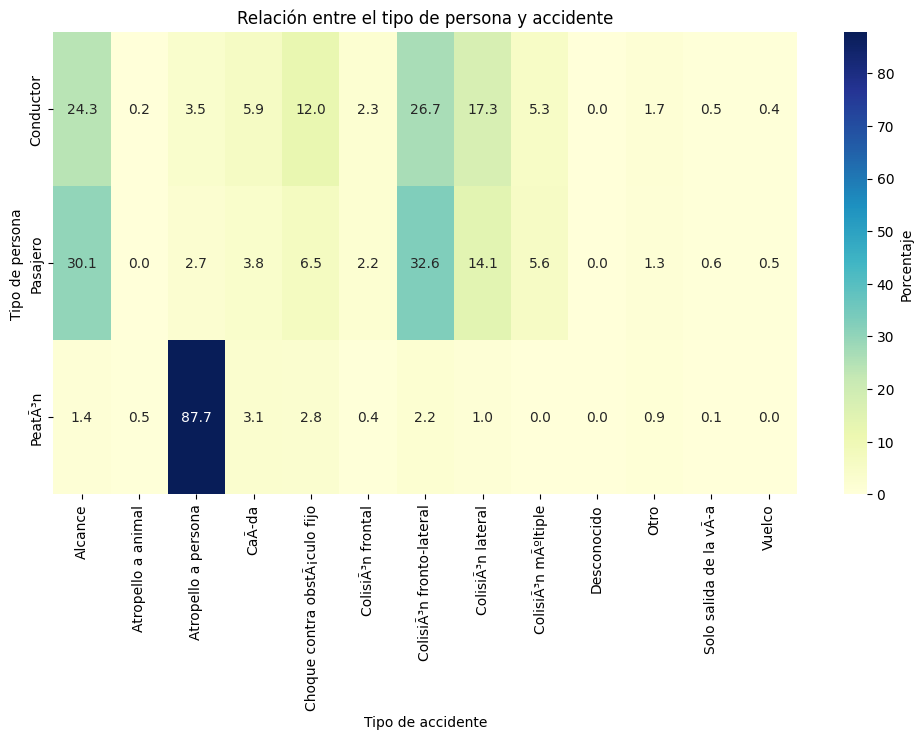

In [11]:
relacion_persona_accidente=pd.crosstab(db['tipo_persona'], db['tipo_accidente'], normalize='index') * 100

plt.figure(figsize=(12, 6))
sns.heatmap(relacion_persona_accidente, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={'label': 'Porcentaje'})

plt.title("Relación entre el tipo de persona y accidente")
plt.xlabel("Tipo de accidente")
plt.ylabel("Tipo de persona")
plt.show()

#### Los peatones son muy propensos en accidentes de atropello y las personas en vehículos a los accidentes de colisiones

### Rango de edad de conducctores en accidentes y rango de edad de gravedad de accidentes

Se obtiene la mayor gravedad de los tipos de lesividad, se filtran solamente los conductores y se obtiene la relación entre edad y gravedad

In [12]:
db['es_grave']=db['cod_lesividad'].isin([3, 4]).astype(int)

df_conductores=db[(db['tipo_persona']=='Conductor') & (db['rango_edad']!='Desconocido')].copy()

frecuencia_edad=df_conductores['rango_edad'].value_counts()

gravedad_edad=df_conductores.groupby('rango_edad')['es_grave'].mean().sort_values(ascending=False) * 100

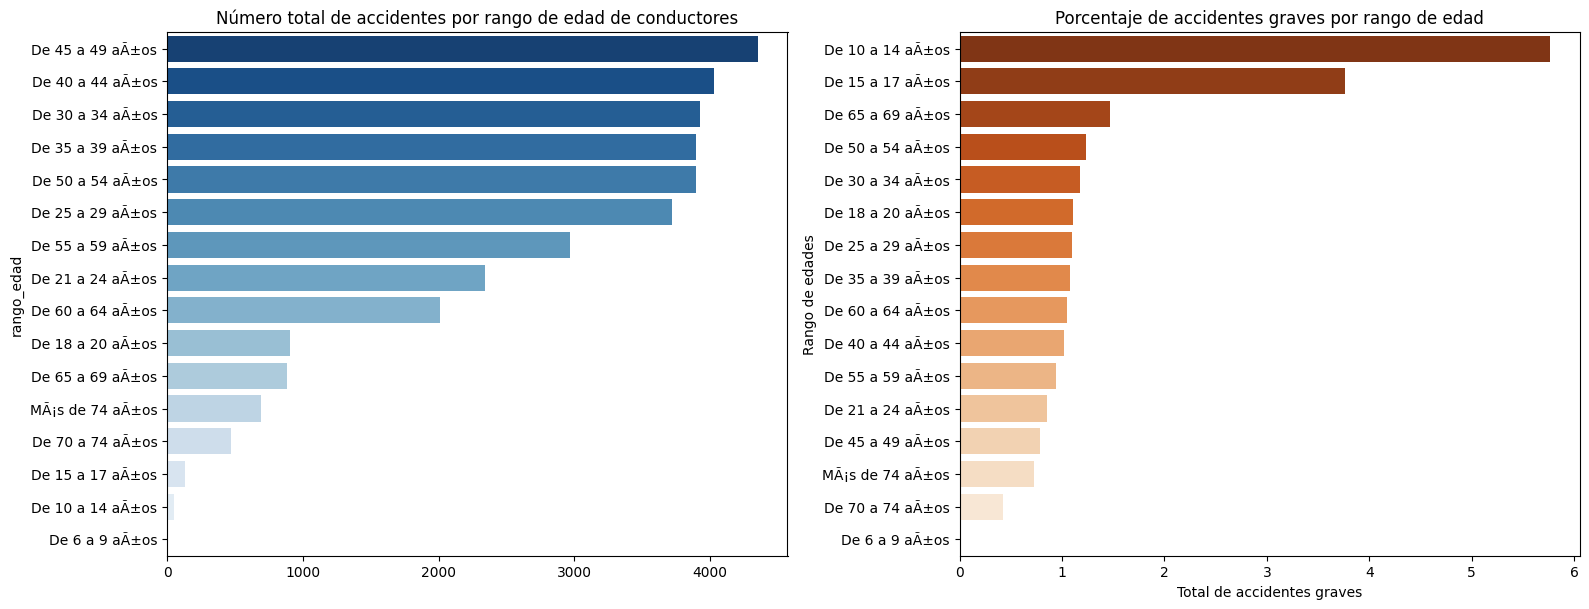

In [13]:
fig, ax=plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    x=frecuencia_edad.values, 
    y=frecuencia_edad.index, 
    hue=frecuencia_edad.index,
    ax=ax[0], 
    palette='Blues_r', 
    legend=False
)

ax[0].set_title("Número total de accidentes por rango de edad de conductores")

sns.barplot(
    x=gravedad_edad.values, 
    y=gravedad_edad.index, 
    hue=gravedad_edad.index,
    ax=ax[1], 
    palette='Oranges_r', 
    legend=False
)

ax[1].set_title("Porcentaje de accidentes graves por rango de edad")

plt.tight_layout()
plt.xlabel("Total de accidentes graves")
plt.ylabel("Rango de edades")
plt.show()

#### El rango de edad de conductores con más accidentes abarca desde los 25 hasta los 54 años, y el rango de edad con mayor tasa de accidentes graves está entre los 10 y 17 años

### Porcentaje de accidentes graves en cada distrito

Se agrupan los distritos y su gravedad

In [14]:
tasa_gravedad=db.groupby('distrito')['es_grave'].mean() * 100
tasa_gravedad=tasa_gravedad.sort_values(ascending=False).reset_index()

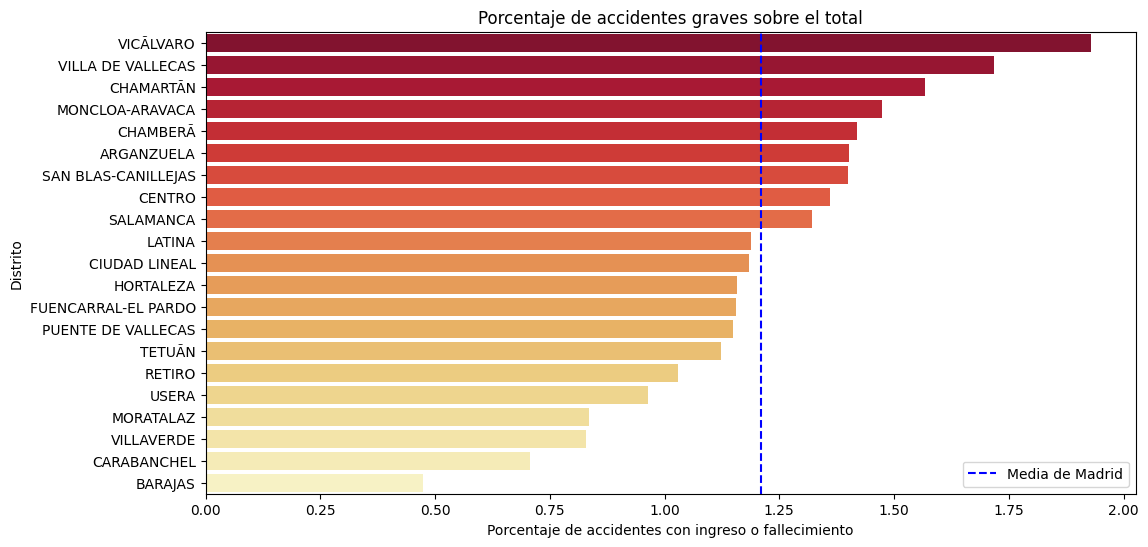

In [15]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=tasa_gravedad, 
    x='es_grave', 
    y='distrito', 
    hue='distrito', 
    palette='YlOrRd_r', 
    legend=False
)

plt.axvline(tasa_gravedad['es_grave'].mean(), color='blue', linestyle='--', label='Media de Madrid')

plt.title("Porcentaje de accidentes graves sobre el total")
plt.xlabel("Porcentaje de accidentes con ingreso o fallecimiento")
plt.ylabel("Distrito")
plt.legend()
plt.show()

#### Los accidentes de mayor gravedad ocurren con mayor frecuencia entre los distritos de Salamanca y Vicálvaro

### Tipos de accidentes más frecuentes

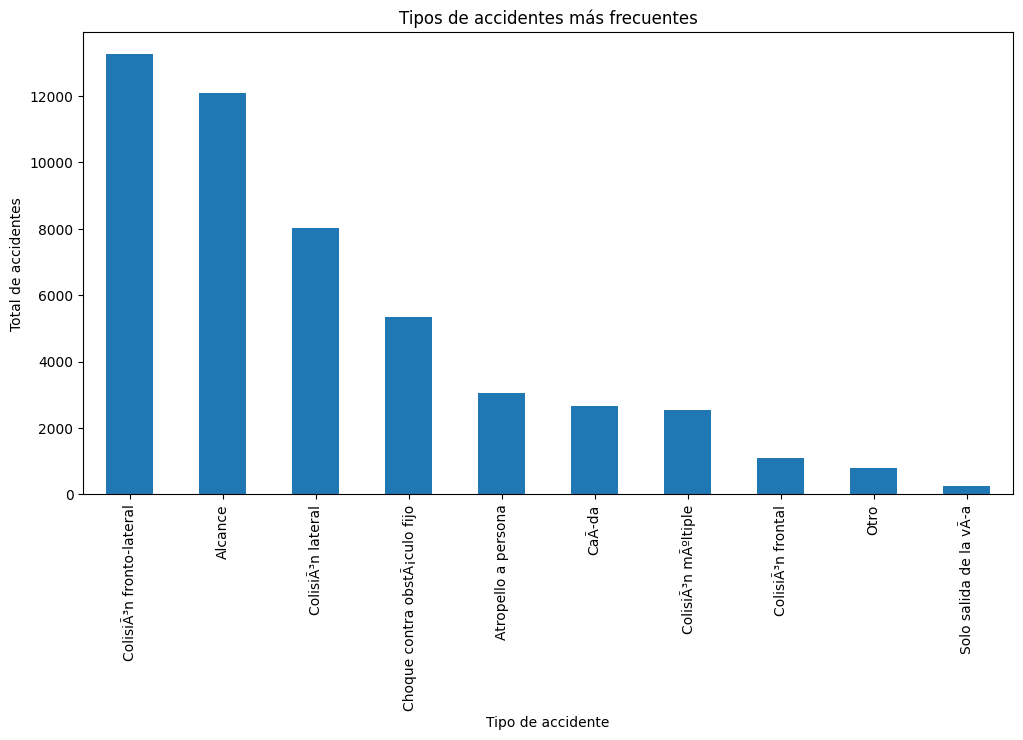

In [16]:
plt.figure(figsize=(12,6))

db['tipo_accidente'].value_counts().head(10).plot(kind='bar')
plt.title('Tipos de accidentes más frecuentes')
plt.xlabel("Tipo de accidente")
plt.ylabel("Total de accidentes")
plt.show()

#### Se muestra que predomina la colisión fronto-lateral y el alcance, mientras que los accidentes causados por sólo salir de la vía son mínimos

### Sexo de las personas implicadas

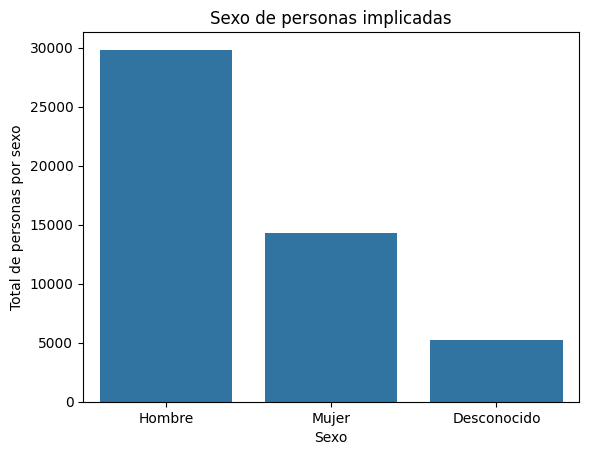

In [17]:
sns.countplot(data=db, x='sexo')
plt.title('Sexo de personas implicadas')
plt.xlabel("Sexo")
plt.ylabel("Total de personas por sexo")
plt.show()

#### Los hombres son los que causan más accidentes de tráfico

### Tipo de personas implicadas

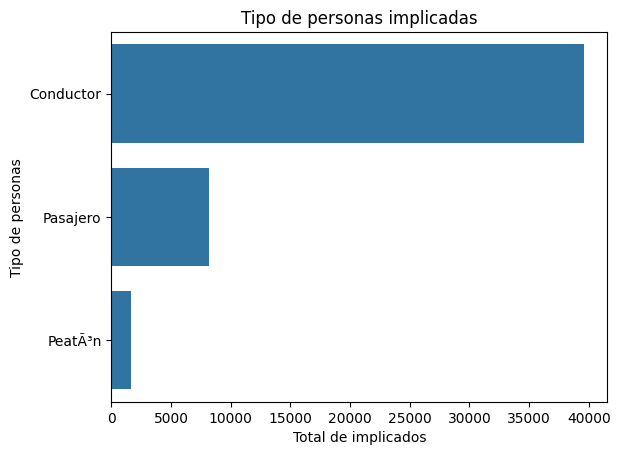

In [18]:
sns.countplot(data=db, y='tipo_persona')
plt.title('Tipo de personas implicadas')
plt.xlabel("Total de implicados")
plt.ylabel("Tipo de personas")
plt.show()

#### Los más implicados en los accidentes son los conductores y en muy pocos casos son los peatones

### Accidentes positivos en alcohol en la madrugada y durante el resto del día

Se obtiene el número de hora, se separa si es de madrugada (entre las 0 y 6), se filtra si es positivo en alcohol y se calcula el porcentaje de positivos por grupo

In [19]:
db['numero_hora']=db['hora'].str.split(':').str[0].astype(int)
db['es_madrugada']=db['numero_hora'].between(0, 6)

df_alc=db[db['positiva_alcohol'].isin(['S', 'N'])].copy()

incidencia_madrugada=df_alc.groupby('es_madrugada')['positiva_alcohol'].apply(lambda x: (x == 'S').mean() * 100).reset_index()

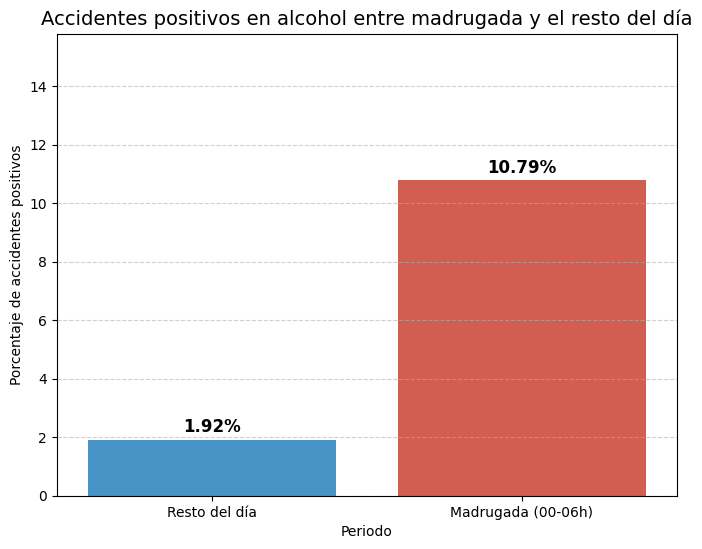

In [20]:
incidencia_madrugada['Periodo']=incidencia_madrugada['es_madrugada'].map({True: 'Madrugada (00-06h)', False: 'Resto del día'})

plt.figure(figsize=(8, 6))

ax=sns.barplot(
    data=incidencia_madrugada, 
    x='Periodo', 
    y='positiva_alcohol', 
    hue='Periodo', 
    palette=['#3498db', '#e74c3c'],
    legend=False
)

for p in ax.patches:

    ax.annotate(f'{p.get_height():.2f}%', 
        (p.get_x() + p.get_width() / 2., p.get_height()), 
        ha='center', va='center', 
        xytext=(0, 9), 
        textcoords='offset points',
        fontsize=12, fontweight='bold')

plt.title('Accidentes positivos en alcohol entre madrugada y el resto del día', fontsize=14)
plt.ylabel('Porcentaje de accidentes positivos')
plt.ylim(0, incidencia_madrugada['positiva_alcohol'].max() + 5)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

#### Los accidentes en la madrugada positivos en alcohol son mayores que durante el resto del día

### Evolución del número de accidentes por mes durante el año

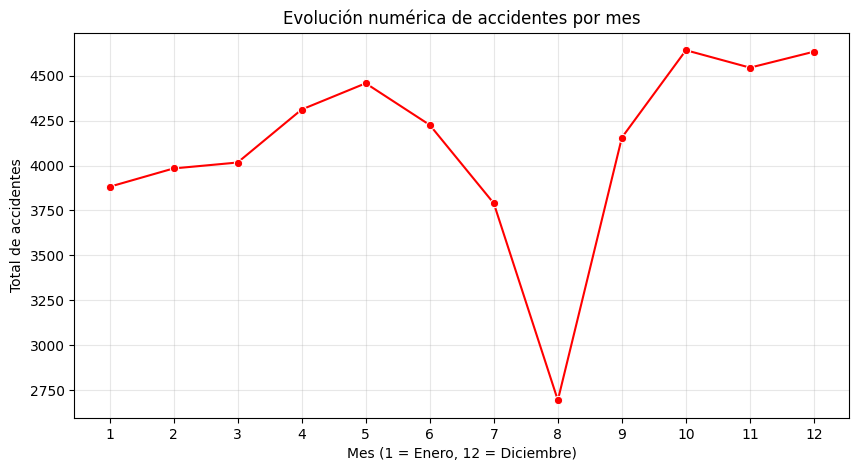

In [21]:
accidentes_mes=db['fecha'].dt.month.value_counts().sort_index()

plt.figure(figsize=(10, 5))
sns.lineplot(x=accidentes_mes.index, y=accidentes_mes.values, marker='o', color='red')
plt.title("Evolución numérica de accidentes por mes")
plt.xlabel("Mes (1 = Enero, 12 = Diciembre)")
plt.ylabel("Total de accidentes")
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.show()

#### El total de accidentes por mes muestra un mínimo en Agosto, donde la mayoría de personas salen afuera de la ciudad por vacaciones, y el máximo es en Diciembre por la congregación por Navidad

## 1.4. Análisis de sesgo geográfico

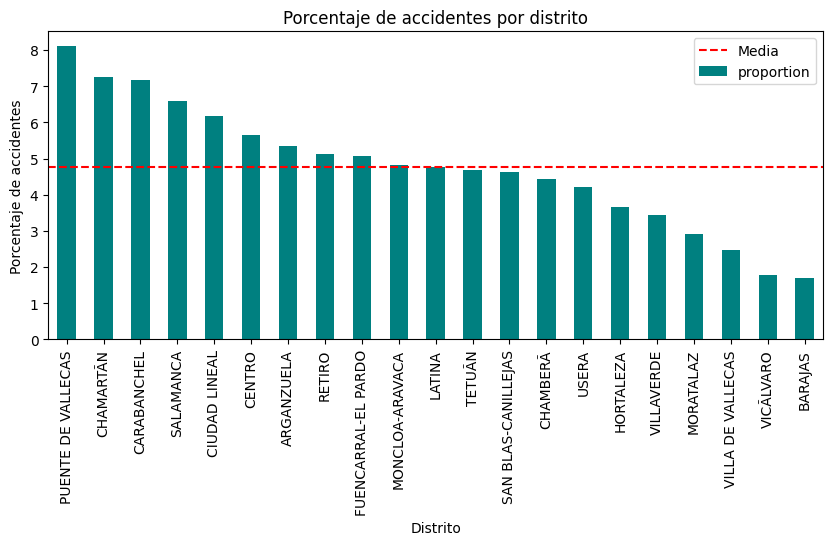

In [22]:
distrito_counts=db['distrito'].value_counts(normalize=True) * 100

distrito_counts.plot(kind='bar', figsize=(10,4), color='teal')
plt.axhline(y=distrito_counts.mean(), color='red', linestyle='--', label='Media')
plt.title("Porcentaje de accidentes por distrito")
plt.ylabel("Porcentaje de accidentes")
plt.xlabel("Distrito")
plt.legend()
plt.show()

#### Se muestra que el número de accidentes son superior en la media entre el Puente de Vallecas y el Centro, esto puede deverse a la densidad de población de cada distrito

## ¿En qué franja horaria se producen los accidentes con mayor gravedad (ingreso superior a 24 horas o fallecidos) y qué condiciones (estado meteorológico, tipo de accidente, etc.) pueden influir en ello?

Se agrupan el número de hora entre distintas franjas horarias

In [23]:
bins=[0, 6, 12, 18, 24]
labels=['Madrugada', 'Mañana', 'Tarde', 'Noche']
db['franja_horaria']=pd.cut(db['numero_hora'], bins=bins, labels=labels, include_lowest=True)

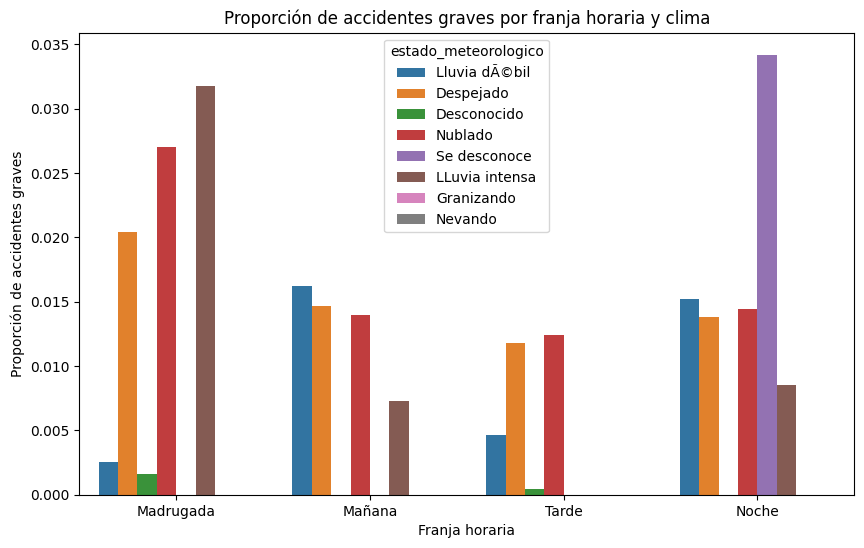

In [24]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=db, 
    x='franja_horaria', 
    y='es_grave', 
    hue='estado_meteorologico', 
    errorbar=None
)

plt.title("Proporción de accidentes graves por franja horaria y clima")
plt.ylabel("Proporción de accidentes graves")
plt.xlabel("Franja horaria")
plt.show()

#### Se muestra que en la noche se generan en mayor número de accidentes de mayor gravedad con un estado metereológico no determinado, seguidos por la madrugada con lluvia intensa y nublado. Esto puede deberse a la conducción en horas de menor visibilidad y/o condiciones metereológicas que empeoran la conducción, como la lluvia o la niebla. 

## 1.5. Conclusión

#### - Los hombres y el rango de edad de 25 a 54 años concentran el mayor volumen total de siniestros. Sin embargo, la tasa de gravedad es especialmente crítica en el sector más joven (10 a 17 años), lo que apunta a una alta vulnerabilidad en ciertos tipos de vehículos o accidentes
#### - Hay una clarísima e incuestionable relación entre la madrugada y la positividad en alcohol. Estacionalmente, diciembre representa el pico anual de siniestralidad (asociado a compras, fiestas y peor clima), mientras que agosto marca el mínimo debido al éxodo vacacional
#### - Distritos de alta densidad y actividad como Puente de Vallecas y Centro lideran el volumen absoluto de accidentes. No obstante, al analizar el porcentaje de gravedad, distritos como Salamanca y Chamartán destacan negativamente, con incidentes severos muy ligados a la conducción nocturna y condiciones climatológicas adversas (lluvia o niebla)

# 2. Modelo de Regresión Logística

El objetivo es utilizar un modelo de Regresión Logística para predecir la variable "positiva_alcohol"

In [25]:
db_modelo=db[
    (db["tipo_persona"]=="Conductor") & (db["positiva_alcohol"].isin(["S", "N"]))
].copy()


db_modelo["target"]=db_modelo["positiva_alcohol"].map({"N": 0, "S": 1})


predictores_categoria=["tipo_accidente", "sexo", "distrito", "estado_meteorologico"]
predictores_numerico=["numero_hora"]

X=db_modelo[predictores_categoria+predictores_numerico]
y=db_modelo["target"]

X_train, X_test, y_train, y_test=train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Tamaño del set de entrenamiento: {X_train.shape[0]} filas")
print(f"Tamaño del set de prueba: {X_test.shape[0]} filas")

Tamaño del set de entrenamiento: 31516 filas
Tamaño del set de prueba: 7880 filas


## 2.1.  Entrenamiento y evaluación


      MÉTRICAS DE RENDIMIENTO DEL MODELO
Accuracy general: 0.7288
F1-Score: 0.1469

Informe de clasificación detallado:
              precision    recall  f1-score   support

           0       0.98      0.73      0.84      7600
           1       0.08      0.66      0.15       280

    accuracy                           0.73      7880
   macro avg       0.53      0.69      0.49      7880
weighted avg       0.95      0.73      0.81      7880



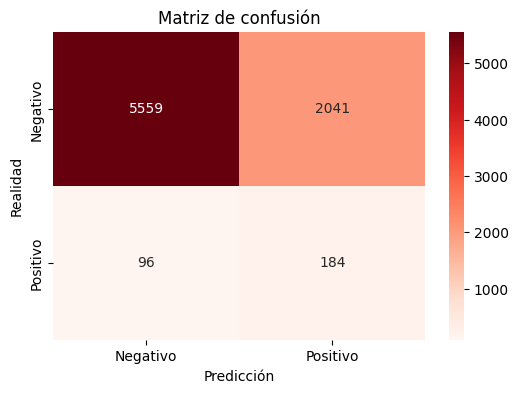

In [26]:
modelo_alcohol=AlcoholLogisticModel(categorical_cols=predictores_categoria, numerical_cols=predictores_numerico, C=1.0)

modelo_alcohol.fit(X_train, y_train)

metricas=modelo_alcohol.evaluate(X_test, y_test)

#### - La precisión es muy baja
#### - La sensibilidad capta dos tercios de conductores realmente positivos en alcohol
#### - f1-score es muy bajo por la precisión

Variables que más incrementan el riesgo de positivo:
                           Característica  Coeficiente
13                            sexo_Hombre     6.219809
14                             sexo_Mujer     5.584394
9              tipo_accidente_Desconocido     2.325443
12                  tipo_accidente_Vuelco     1.970986
11  tipo_accidente_Solo salida de la vÃ­a     1.838978

Variables que más disminuyen el riesgo de positivo:
                         Característica  Coeficiente
40         estado_meteorologico_Nublado    -0.256430
15                     distrito_BARAJAS    -0.302296
37  estado_meteorologico_LLuvia intensa    -0.378908
10                  tipo_accidente_Otro    -0.468749
1     tipo_accidente_Atropello a animal    -1.881108


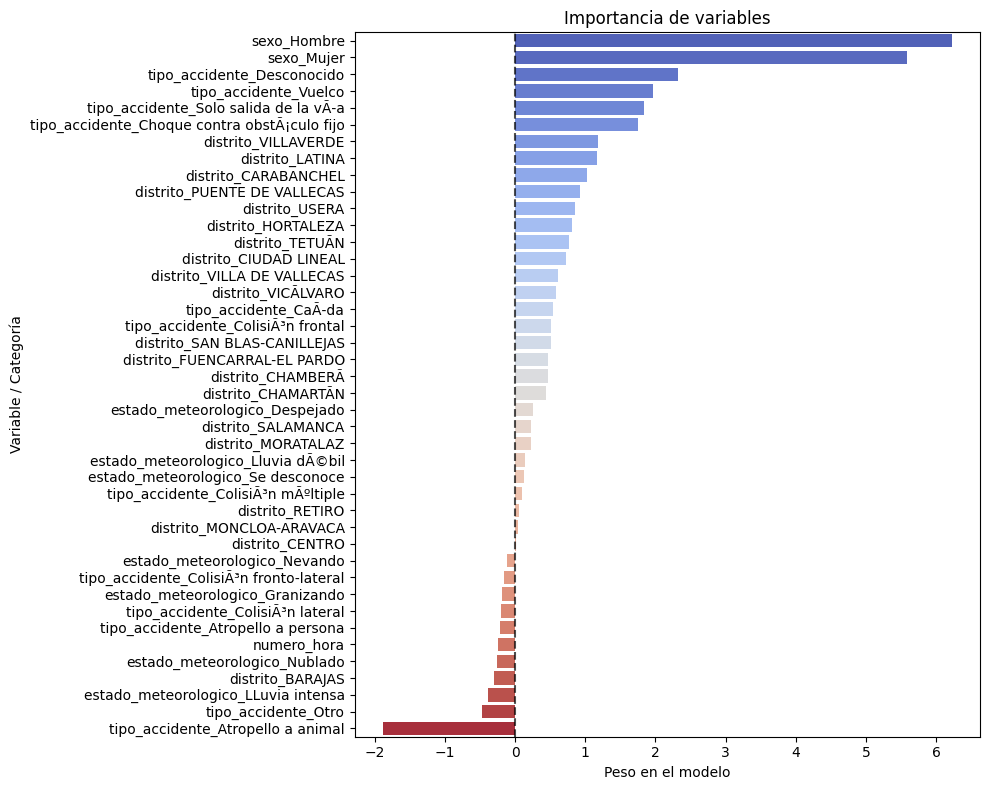

In [27]:
importancias=modelo_alcohol.get_feature_importance()

print("Variables que más incrementan el riesgo de positivo:")
print(importancias.head(5))

print("\nVariables que más disminuyen el riesgo de positivo:")
print(importancias.tail(5))

plt.figure(figsize=(10, 8))
sns.barplot(
    data=importancias,
    x="Coeficiente",
    y="Característica",
    hue="Característica",
    palette="coolwarm",
    legend=False,
)

plt.axvline(0, color="black", linestyle="--", alpha=0.7)
plt.title("Importancia de variables")
plt.xlabel("Peso en el modelo")
plt.ylabel("Variable / Categoría")
plt.tight_layout()
plt.show()

#### Las variables que más peso tienen en relación al positivo de alcohol son los tipos de accidentes por la pérdida de capacidad motora y concentración al conductor, además de que en determinados distritos de la ciudad es más probable que se relacione un accidente positivo en alcohol